# TEP comparison figures

Run the TEP primary, baseline, score-ablation, and alarm-ablation evaluation notebooks first. This notebook creates TEP detection, model-complexity, and combined score/alarm ablation figures. The existing results_figures notebook creates the aggregate TEP recovery figure.


In [1]:
from pathlib import Path
import sys


def find_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "reports").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TEP_METRICS = PROJECT_ROOT / "reports" / "results" / "TEP" / "figure_metrics"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not TEP_METRICS.is_dir():
    raise FileNotFoundError(
        "TEP figure metrics are missing. Run the TEP evaluation notebooks with their export cells first."
    )

def load_metrics(experiment, partition):
    paths = sorted(TEP_METRICS.glob(f"{experiment}_*_{partition}.csv"))
    if not paths:
        raise FileNotFoundError(
            f"No {partition} exports found for {experiment}. Run the corresponding TEP evaluation notebooks first."
        )
    return pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)


def save_figure(fig, stem):
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight")
    print(f"Saved {stem}.png and {stem}.pdf")


plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

Saved tep_detection_complexity.png and tep_detection_complexity.pdf


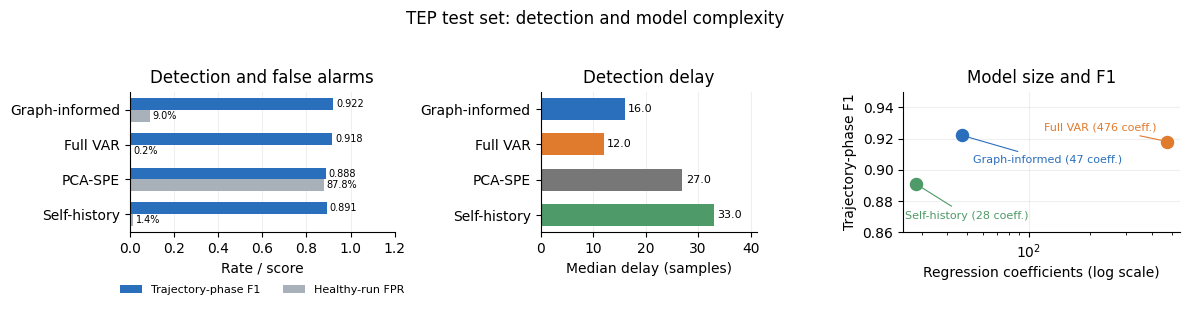

(           Method  Trajectory-Phase F1  Trajectory-Phase TPR  \
 0  Graph-informed             0.922124                0.8709   
 1        Full VAR             0.918102                0.8503   
 2         PCA-SPE             0.888432                0.9719   
 3    Self-history             0.891098                0.8068   
 
    Healthy Test Trajectory-Phase FPR  Median Anomaly Detection Delay  
 0                              0.090                            16.0  
 1                              0.002                            12.0  
 2                              0.878                            27.0  
 3                              0.014                            33.0  ,
                 Coefficient count
 Graph-informed                 47
 Full VAR                      476
 Self-history                   28)

In [2]:
faulty = load_metrics("main_detection", "faulty_test")
healthy = load_metrics("main_detection", "healthy_test")
main = faulty.merge(healthy[["Method", "Trajectory-Phase FPR"]].rename(columns={"Trajectory-Phase FPR": "Healthy Test Trajectory-Phase FPR"}), on="Method", how="left", validate="one_to_one")
method_order = ["Graph-informed", "Full VAR", "PCA-SPE", "Self-history"]
main["Method"] = pd.Categorical(main["Method"], method_order, ordered=True)
main = main.sort_values("Method").reset_index(drop=True)
if main["Healthy Test Trajectory-Phase FPR"].isna().any():
    missing = main.loc[main["Healthy Test Trajectory-Phase FPR"].isna(), "Method"].astype(str).tolist()
    raise ValueError(f"Missing healthy-test false-alarm metrics for: {', '.join(missing)}")

training = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "TEP" / "TEP_Training.parquet")
feature_names = [name for name in training.columns if name not in {"faultNumber", "simulationRun", "sample"}]
adjacency = np.loadtxt(PROJECT_ROOT / "references" / "TEP" / "TEGroundTruth.txt")
if adjacency.shape != (len(feature_names), len(feature_names)):
    raise ValueError("The TEP graph dimensions do not match the retained process-variable columns.")
process_children = [child for child_idx, child in enumerate(feature_names) if int(child[1:]) < 23 and adjacency[:, child_idx].sum() > 0]
weight_roots = {
    "Graph-informed": PROJECT_ROOT / "models" / "TEP" / "max_lag_selection" / "weights",
    "Full VAR": PROJECT_ROOT / "models" / "TEP" / "anomaly_detection_baseline_full_var" / "weights",
    "Self-history": PROJECT_ROOT / "models" / "TEP" / "anomaly_detection_baseline_self_history" / "weights",
}
parameter_counts = {}
for method, weight_root in weight_roots.items():
    arrays = [weight_root / f"beta_child_{child}_lag_1.npy" for child in process_children]
    missing = [path for path in arrays if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing fitted coefficient arrays for {method}: {missing}")
    parameter_counts[method] = sum(np.load(path).size for path in arrays)

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), gridspec_kw={"width_ratios": [1.1, 0.9, 1.15]})
method_colors = {"Graph-informed": "#2A6FBB", "Full VAR": "#E07A2D", "PCA-SPE": "#777777", "Self-history": "#4E9A68"}
y = np.arange(len(main))
bar_height = 0.34
f1_values = main["Trajectory-Phase F1"].astype(float).to_numpy()
healthy_fpr_values = main["Healthy Test Trajectory-Phase FPR"].astype(float).to_numpy()
axes[0].barh(y - bar_height / 2, f1_values, height=bar_height, color="#2A6FBB", label="Trajectory-phase F1")
axes[0].barh(y + bar_height / 2, healthy_fpr_values, height=bar_height, color="#A8B0BA", label="Healthy-run FPR")
axes[0].set_yticks(y, main["Method"].astype(str))
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.2)
axes[0].set_xlabel("Rate / score")
axes[0].set_title("Detection and false alarms")
axes[0].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
axes[0].grid(axis="x", alpha=0.2)
axes[0].set_axisbelow(True)
for yi, f1_value, fpr_value in zip(y, f1_values, healthy_fpr_values, strict=True):
    axes[0].text(f1_value + 0.012, yi - bar_height / 2, f"{f1_value:.3f}", va="center", fontsize=7)
    axes[0].text(fpr_value + 0.012, yi + bar_height / 2, f"{fpr_value:.1%}", va="center", fontsize=7)

delay_values = main["Median Anomaly Detection Delay"].astype(float).to_numpy()
axes[1].barh(y, delay_values, color=[method_colors[str(method)] for method in main["Method"]], height=0.62)
axes[1].set_yticks(y, main["Method"].astype(str))
axes[1].invert_yaxis()
axes[1].set_xlabel("Median delay (samples)")
axes[1].set_title("Detection delay")
axes[1].set_xlim(0, max(delay_values) * 1.25)
axes[1].grid(axis="x", alpha=0.2)
axes[1].set_axisbelow(True)
for yi, value in zip(y, delay_values, strict=True):
    axes[1].text(value + max(delay_values) * 0.02, yi, f"{value:.1f}", va="center", fontsize=8)

complexity = main.loc[main["Method"].astype(str).isin(parameter_counts)].copy()
complexity["Coefficient count"] = complexity["Method"].astype(str).map(parameter_counts)
label_offsets = {"Graph-informed": (8, -20), "Full VAR": (-8, 8), "Self-history": (-8, -25)}
for _, row in complexity.iterrows():
    method = str(row["Method"])
    axes[2].scatter(row["Coefficient count"], row["Trajectory-Phase F1"], s=75, color=method_colors[method], zorder=3)
    axes[2].annotate(f"{method} ({int(row['Coefficient count'])} coeff.)", (row["Coefficient count"], row["Trajectory-Phase F1"]), xytext=label_offsets[method], textcoords="offset points", ha="right" if method == "Full VAR" else "left", color=method_colors[method], arrowprops={"arrowstyle": "-", "color": method_colors[method], "lw": 0.8}, fontsize=8)
axes[2].set_xscale("log")
axes[2].set_xlabel("Regression coefficients (log scale)")
axes[2].set_ylabel("Trajectory-phase F1")
axes[2].set_ylim(0.86, 0.95)
axes[2].set_title("Model size and F1")
axes[2].grid(alpha=0.2)
axes[2].set_axisbelow(True)
fig.suptitle("TEP test set: detection and model complexity", y=1.03, fontsize=12)
fig.tight_layout(rect=(0, 0.11, 1, 1))
save_figure(fig, "tep_detection_complexity")
plt.show()
main[["Method", "Trajectory-Phase F1", "Trajectory-Phase TPR", "Healthy Test Trajectory-Phase FPR", "Median Anomaly Detection Delay"]], pd.Series(parameter_counts, name="Coefficient count").to_frame()


Saved tep_ablation_summary.png and tep_ablation_summary.pdf


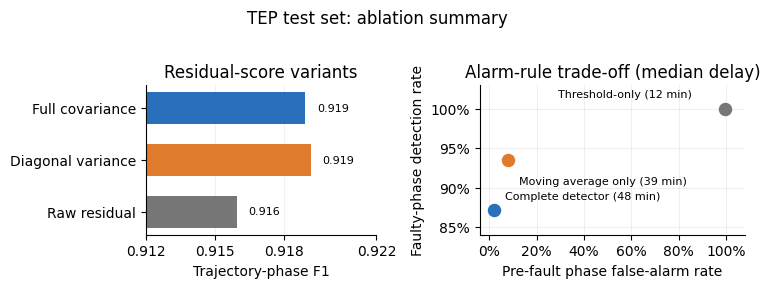

(              Method  Trajectory-Phase F1  Median Anomaly Detection Delay
 0    Full covariance             0.918919                            12.0
 1  Diagonal variance             0.919153                            14.0
 2       Raw residual             0.915942                            19.0,
                 Method  Trajectory-Phase TPR  Trajectory-Phase FPR  \
 0    Complete detector                0.8709                 0.018   
 1  Moving average only                0.9356                 0.078   
 2       Threshold-only                1.0000                 0.996   
 
    Median Anomaly Detection Delay  
 0                            16.0  
 1                            13.0  
 2                             4.0  )

In [3]:
score_faulty = load_metrics("score_ablations", "faulty_test")
score_healthy = load_metrics("score_ablations", "healthy_test")
score = score_faulty.merge(score_healthy[["Method", "Trajectory-Phase FPR"]].rename(columns={"Trajectory-Phase FPR": "Healthy Test Trajectory-Phase FPR"}), on="Method", how="left", validate="one_to_one")
score_order = ["Full covariance", "Diagonal variance", "Raw residual"]
score["Method"] = pd.Categorical(score["Method"], score_order, ordered=True)
score = score.sort_values("Method").reset_index(drop=True)
alarm = load_metrics("alarm_ablations", "faulty_test")
alarm_order = ["Complete detector", "Moving average only", "Threshold-only"]
alarm["Method"] = pd.Categorical(alarm["Method"], alarm_order, ordered=True)
alarm = alarm.sort_values("Method").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(7.65, 2.78), gridspec_kw={"width_ratios": [1.0, 1.15]})
y = np.arange(len(score))
score_values = score["Trajectory-Phase F1"].astype(float).to_numpy()
score_axis_min = 0.912
axes[0].barh(y, score_values - score_axis_min, left=score_axis_min, color=["#2A6FBB", "#E07A2D", "#777777"], height=0.62)
axes[0].set_yticks(y, score["Method"].astype(str))
axes[0].invert_yaxis()
axes[0].set_xlim(score_axis_min, 0.922)
axes[0].set_xticks([0.912, 0.915, 0.918, 0.922])
axes[0].set_xlabel("Trajectory-phase F1")
axes[0].set_title("Residual-score variants")
axes[0].grid(axis="x", alpha=0.2)
axes[0].set_axisbelow(True)
for yi, row in score.iterrows():
    axes[0].text(float(row["Trajectory-Phase F1"]) + 0.0005, yi, f"{row['Trajectory-Phase F1']:.3f}", va="center", fontsize=8)

alarm_colors = {"Complete detector": "#2A6FBB", "Moving average only": "#E07A2D", "Threshold-only": "#777777"}
alarm_offsets = {"Complete detector": (8, 8), "Moving average only": (8, -18), "Threshold-only": (-120, 8)}
for _, row in alarm.iterrows():
    axes[1].scatter(row["Trajectory-Phase FPR"], row["Trajectory-Phase TPR"], s=75, color=alarm_colors[str(row["Method"])], zorder=3)
    axes[1].annotate(f"{row['Method']} ({row['Median Anomaly Detection Delay'] * 3:.0f} min)", (row["Trajectory-Phase FPR"], row["Trajectory-Phase TPR"]), xytext=alarm_offsets[str(row["Method"])], textcoords="offset points", fontsize=8)
axes[1].set_xlim(-0.04, 1.08)
axes[1].set_ylim(0.84, 1.03)
axes[1].set_xlabel("Pre-fault phase false-alarm rate")
axes[1].set_ylabel("Faulty-phase detection rate")
axes[1].set_title("Alarm-rule trade-off (median delay)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[1].grid(alpha=0.2)
axes[1].set_axisbelow(True)
fig.suptitle("TEP test set: ablation summary", y=1.02, fontsize=12)
fig.tight_layout()
save_figure(fig, "tep_ablation_summary")
plt.show()
score[["Method", "Trajectory-Phase F1", "Median Anomaly Detection Delay"]], alarm[["Method", "Trajectory-Phase TPR", "Trajectory-Phase FPR", "Median Anomaly Detection Delay"]]
